# PASO 1 :Exploración de Datos, Valores Faltantes y Outliers con Python

**Objetivo:** Navegar a través de los datos del dataset seleccionado, investigar relación entre ellos, buscar valores nulos o columnas que generan ruido

**Stack:** `sys`, `os`, `warnings`, `pandas`, `numpy`, `matplotlib`, `seaborn`

> Al terminar exportamos la versión limpia como `Dataset_clean.csv`

In [118]:
import sys
import os

# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Importa la función desde helpers.py
from helpers import formato_moneda

In [119]:
# Remueve cualquier tipo de advertencia de FutureWarning
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [120]:
# Carga de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga del dataset
raw = pd.read_csv("../data/ENCUESTA_DE_REMUNERACION_SALARIAL_IT_ARGENTINA_2026.csv")

# Inspección rápida de dimensiones y primeras filas
print(f"Dimensiones del dataset: {raw.shape[0]} filas y {raw.shape[1]} columnas.")
display(raw.head(3))

# Vemos cantidad de trabajos por categoría
print("Cantidad de trabajos por categoría:")
display(raw['trabajo_de'].value_counts().to_frame("Cantidad"))

# Vemos cantidad de trabajos por modalidad de trabajo
print("Cantidad de trabajos por modalidad de trabajo:")
display(raw['modalidad_de_trabajo'].value_counts().to_frame("Cantidad"))

# Vemos cantidad de sueldos no dolarizados y dolarizados
print("Cantidad de trabajos por modalidad de trabajo:")
display(raw['sueldo_dolarizado'].value_counts().to_frame("Cantidad"))

Dimensiones del dataset: 4939 filas y 60 columnas.


,donde_estas_trabajando,dedicacion,tipo_de_contrato,ultimo_salario_mensual_o_retiro_bruto_en_pesos_argentinos,ultimo_salario_mensual_o_retiro_neto_en_pesos_argentinos,pagos_en_dolares,si_tu_sueldo_esta_dolarizado_cual_fue_el_ultimo_valor_del_dolar_que_tomaron,recibis_algun_tipo_de_bono,a_que_esta_atado_el_bono,tuviste_actualizaciones_de_tus_ingresos_laborales_durante_el_ultimo_semestre,...,cuanto_cobras_por_guardia,aclara_el_numero_que_ingresaste_en_el_campo_anterior,salir_o_seguir_contestando_sobre_estudios,tengo_edad,genero,habias_respondido_nuestra_encuesta_en_ediciones_anteriores,cuales_consideras_que_son_las_mejores_empresas_de_it_para_trabajar_en_este_momento_en_tu_ciudad,sueldo_dolarizado,seniority,_sal
0,Mendoza,Full-Time,Staff (planta permanente),3000000.0,2400000.0,Mi sueldo está dolarizado (pero cobro en moned...,1300,No,Performance individual,No,...,NaN,NaN,NaN,45,Mujer Cis,Sí,NaN,True,Senior,3000000.0
1,Santa Fe,Full-Time,Contractor,5000000.0,5000000.0,Cobro todo el salario en dólares,1400,No,No recibo bono,No,...,NaN,NaN,NaN,50,Mujer Cis,Sí,NaN,True,Senior,5000000.0
2,Buenos Aires,Full-Time,Tercerizado (trabajo a través de consultora o ...,4600000.0,3600000.0,Cobro parte del salario en dólares,1436,No,No recibo bono,Uno,...,0.0,Porcentaje de mi sueldo bruto,Terminar encuesta,36,Mujer Cis,Sí,NaN,True,Senior,4600000.0


Cantidad de trabajos por categoría:


,Cantidad
trabajo_de,
Developer,1666
SysAdmin / DevOps / SRE,555
Manager / Director,443
Technical Leader,356
QA / Tester,237
...,...
Service Delivery Analist,1
Tech Engineer sr,1
"SME z/OS, Mq y PGM PROD",1


Cantidad de trabajos por modalidad de trabajo:


,Cantidad
modalidad_de_trabajo,
100% remoto,2352
Híbrido (presencial y remoto),2160
100% presencial,427


Cantidad de trabajos por modalidad de trabajo:


,Cantidad
sueldo_dolarizado,
False,3356
True,1583


#### Selección Estratégica de Variables

El dataset al ser proveniente de encuesta del sector tenológico (Sysarmy), es muy común encontrarse con una gran cantidad de columnas. Sin embargo, no toda la información disponible es útil para predecir nuestra variable objetivo (`_sal` / `salario`).

Una encuesta de esta naturaleza suele abarcar múltiples dimensiones que van desde el **contexto laboral y la compensación** hasta **opiniones subjetivas, procesos de selección, beneficios adicionales, satisfacción personal y herramientas accesorias**.

Por eso nos interesa retener únicamente las variables que empíricamente y por lógica de negocio explican la remuneración: **la experiencia, el rol, el seniority, la ubicación geográfica, las tecnologías utilizadas y el tipo de contratación**.

In [121]:
# 1. Definición de las columnas que queremos conservar para el análisis, agrupadas por categoría
columnas_a_conservar = [
    # --- UBICACIÓN Y CONTEXTO GEOGRÁFICO ---
    'donde_estas_trabajando',
    # --- CONDICIONES LABORALES Y CONTRATO ---
    'dedicacion',
    'tipo_de_contrato',
    'modalidad_de_trabajo',
    'sueldo_dolarizado',
    # --- BENEFICIOS Y SITUACIÓN LABORAL ---
    'contas_con_beneficios_adicionales',
    'estas_buscando_trabajo',
    'tenes_guardias',
    # --- ROL Y EXPERIENCIA ---
    'trabajo_de',
    'seniority',
    'anos_de_experiencia',
    'antiguedad_en_la_empresa_actual',
    'anos_en_el_puesto_actual',
    # --- STACK TECNOLÓGICO Y HERRAMIENTAS ---
    'plataformas_que_utilizas_en_tu_puesto_actual',
    'lenguajes_de_programacion_o_tecnologias_que_utilices_en_tu_puesto_actual',
    'frameworksherramientas_y_librerias_que_utilices_en_tu_puesto_actual',
    'bases_de_datos',
    'qa_testing',
    # --- ORGANIZACIÓN Y EMPRESA ---
    'cantidad_de_personas_en_tu_organizacion',
    # --- EDUCACIÓN Y PERFIL DEMOGRÁFICO ---
    'maximo_nivel_de_estudios',
    'estado',
    'carrera',
    'tengo_edad',
    'genero',
    # --- TARGET ---
    '_sal',
]

# Validamos qué columnas de la lista realmente existen en el dataset original ('raw')
columnas_existentes = [
    col for col in columnas_a_conservar if col in raw.columns
]
columnas_faltantes = [
    col for col in columnas_a_conservar if col not in raw.columns
]

if columnas_faltantes:
    print(
        'Aviso: Las siguientes columnas no se encontraron en el dataset y'
        f' fueron omitidas: {columnas_faltantes}\n'
    )

# Filtramos el dataframe quedándonos exclusivamente con las deseadas
df = raw[columnas_existentes].copy()

# Renombramos '_sal' a 'salario' si está presente
if '_sal' in df.columns:
  df = df.rename(columns={'_sal': 'salario'})

print(
    f'¡Dataset filtrado con éxito! Dimensiones resultantes: {df.shape[0]} filas'
    f' y {df.shape[1]} columnas.'
)
display(df.head(3))

¡Dataset filtrado con éxito! Dimensiones resultantes: 4939 filas y 25 columnas.


,donde_estas_trabajando,dedicacion,tipo_de_contrato,modalidad_de_trabajo,sueldo_dolarizado,contas_con_beneficios_adicionales,estas_buscando_trabajo,tenes_guardias,trabajo_de,seniority,...,frameworksherramientas_y_librerias_que_utilices_en_tu_puesto_actual,bases_de_datos,qa_testing,cantidad_de_personas_en_tu_organizacion,maximo_nivel_de_estudios,estado,carrera,tengo_edad,genero,salario
0,Mendoza,Full-Time,Staff (planta permanente),Híbrido (presencial y remoto),True,"Capacitaciones y/o cursos, Descuento en gimnas...","No, pero escucho ofertas.",NaN,Developer,Senior,...,".NET Core, Bootstrap, Hibernate, jQuery, Next....","Amazon DynamoDB, ElasticSearch, Google Cloud S...","JUnit, Selenium",De 1001 a 2000 personas,NaN,NaN,NaN,45,Mujer Cis,3000000.0
1,Santa Fe,Full-Time,Contractor,100% remoto,True,Ninguna de las anteriores,"No, estoy muy conforme.",NaN,Developer,Senior,...,".NET Core, Bootstrap, Node.js, Vue.js",Microsoft SQL Server,Postman,De 51 a 100 personas,NaN,NaN,NaN,50,Mujer Cis,5000000.0
2,Buenos Aires,Full-Time,Tercerizado (trabajo a través de consultora o ...,100% remoto,True,"Abono de Internet, Clases de idiomas, Crédito ...","No, pero escucho ofertas.",No,Developer,Senior,...,Flutter,Amazon RDS/Aurora,Postman,De 51 a 100 personas,Universitario,Completo,Ingeniería en Sistemas de Información,36,Mujer Cis,4600000.0


#### Discriminación de Columnas por Tipo

In [122]:
# Columnas y sus tipos de datos
print(df.dtypes)

donde_estas_trabajando                                                          str
dedicacion                                                                      str
tipo_de_contrato                                                                str
modalidad_de_trabajo                                                            str
sueldo_dolarizado                                                              bool
contas_con_beneficios_adicionales                                               str
estas_buscando_trabajo                                                          str
tenes_guardias                                                                  str
trabajo_de                                                                      str
seniority                                                                       str
anos_de_experiencia                                                           int64
antiguedad_en_la_empresa_actual                                             

In [123]:
# Selección de columnas por tipo
num_cols = [col for col in df.columns if pd.api.types.is_numeric_dtype(df[col])]
cat_cols = [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])]

print("Cantidad de columnas numéricas:", len(num_cols))
print("Numéricas:", num_cols)
print("-" * 100)
print("Cantidad de columnas categóricas:", len(cat_cols))
print("Categóricas:", cat_cols)

Cantidad de columnas numéricas: 6
Numéricas: ['sueldo_dolarizado', 'anos_de_experiencia', 'antiguedad_en_la_empresa_actual', 'anos_en_el_puesto_actual', 'tengo_edad', 'salario']
----------------------------------------------------------------------------------------------------
Cantidad de columnas categóricas: 19
Categóricas: ['donde_estas_trabajando', 'dedicacion', 'tipo_de_contrato', 'modalidad_de_trabajo', 'contas_con_beneficios_adicionales', 'estas_buscando_trabajo', 'tenes_guardias', 'trabajo_de', 'seniority', 'plataformas_que_utilizas_en_tu_puesto_actual', 'lenguajes_de_programacion_o_tecnologias_que_utilices_en_tu_puesto_actual', 'frameworksherramientas_y_librerias_que_utilices_en_tu_puesto_actual', 'bases_de_datos', 'qa_testing', 'cantidad_de_personas_en_tu_organizacion', 'maximo_nivel_de_estudios', 'estado', 'carrera', 'genero']


#### Detección de Outliers

**Objetivo:** Los salarios en el sector IT suelen tener distribuciones sesgadas con valores extremos altos. Aplicaremos tres metodologías distintas para detectar outliers en la variable salarial (`salario`):

1. **Rango Intercuartil (IQR)**: Basado en Q1 y Q3 (1.5 x IQR).
2. **Z-Score**: Basado en desviaciones estándar respecto a la media,.
3. **Percentiles**:  Observaremos la media por cada quartil (25%, 50%, 75%, 100%) y los extremos (1% y 99%).

In [124]:
# 1. Método IQR
Q1 = df['salario'].quantile(0.25)
Q3 = df['salario'].quantile(0.75)
IQR = Q3 - Q1
lim_inf_iqr = Q1 - 1.5 * IQR
lim_sup_iqr = Q3 + 1.5 * IQR
outliers_iqr = df[(df['salario'] < lim_inf_iqr) | (df['salario'] > lim_sup_iqr)]

print(f"Outliers detectados por IQR: {len(outliers_iqr)}")

# 2. Método Z-Score
mean_salario = df['salario'].mean()
std_salario = df['salario'].std()
z_scores = np.abs((df['salario'] - mean_salario) / std_salario)
outliers_zscore = df[z_scores > 3]

print(f"Outliers detectados por Z-Score: {len(outliers_zscore)}")

# 3. Método de Percentiles (1% y 99%)
display(df[num_cols].describe().T.round(2))
display(df[cat_cols].describe().T)

# Filtrar num_cols para excluir los booleanos que rompen el cálculo de cuantiles
num_cols_puro = [col for col in num_cols if df[col].dtype != bool]

# Percentiles extra (útiles para colas)
percentiles = df[num_cols_puro].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
print("Percentiles clave:")
display(percentiles.round(2))

Outliers detectados por IQR: 202
Outliers detectados por Z-Score: 89


,count,mean,std,min,25%,50%,75%,max
anos_de_experiencia,4939.0,10.11,8.26,0.0,4.00,7.0,15.0,48.0
antiguedad_en_la_empresa_actual,4939.0,4.52,5.32,0.0,1.00,3.0,5.0,43.0
anos_en_el_puesto_actual,4939.0,3.60,4.01,0.0,1.00,3.0,5.0,40.0
tengo_edad,4939.0,37.51,18.64,16.0,30.00,36.0,43.0,999.0
salario,4939.0,3876029.08,2492699.24,200000.0,2166335.66,3268000.0,4944960.0,20000000.0


,count,unique,top,freq
donde_estas_trabajando,4939,24,Ciudad Autónoma de Buenos Aires,2476
dedicacion,4939,2,Full-Time,4724
tipo_de_contrato,4939,5,Staff (planta permanente),3526
modalidad_de_trabajo,4939,3,100% remoto,2352
contas_con_beneficios_adicionales,4939,1734,Ninguna de las anteriores,798
estas_buscando_trabajo,4939,3,"No, pero escucho ofertas.",3205
tenes_guardias,1140,3,No,654
trabajo_de,4939,105,Developer,1666
seniority,4939,3,Senior,2892
plataformas_que_utilizas_en_tu_puesto_actual,4939,1207,Ninguna de las anteriores,875


Percentiles clave:


,0.01,0.05,0.25,0.50,0.75,0.95,0.99
anos_de_experiencia,0.0,2.0,4.00,7.0,15.0,27.0,35.0
antiguedad_en_la_empresa_actual,0.0,0.0,1.00,3.0,5.0,16.0,25.0
anos_en_el_puesto_actual,0.0,0.0,1.00,3.0,5.0,10.0,20.0
tengo_edad,22.0,25.0,30.00,36.0,43.0,53.0,62.0
salario,580000.0,1120950.4,2166335.66,3268000.0,4944960.0,8700000.0,12978340.0


#### Conclusiones de Outliers:
* **IQR**: Encontró un total de 202 salarios altos o extremos.
* **Z-Score**: Detectó 89 desviaciones alejadas de la media
* En la columna `tengo_edad` encontramos un máximo de 999 años, valor que debemos filtrar posteriormente.
* Se nota una asimetría salarial. `salario` está sesgado hacia la derecha por unos pocos salarios muy altos que tiran el promedio hacia arriba.


#### En el siguiente módulo realizaremos lo siguiente. 

1. **Limpieza de Valores Extremos:** Aplicamos un filtro eliminando el 1% inferior y el 1% superior de `salarios` para evitar que los valores atípicos distorsionen las métricas.
2. **Estandarización y Filtrado:** Nos concentramos exclusivamente en jornadas a tiempo completo (*Full-Time*) y estandarizamos las variables de texto.

A continuación, visualizamos la distribución mediante un diagrama de cajas (*boxplot*) y su respectiva tabla con formato monetario argentino:

In [125]:
# Estandarización de Texto en Categóricas
# Unificamos formatos de texto eliminando espacios sobrantes y estandarizando mayúsculas/minúsculas
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

# Realizamos una copia para hacer la comparativa de antes y después de la limpieza
df_antes_iqr = df.copy()

# Eliminamos registros con una edad mayor a 150 años
df = df[df['tengo_edad'] <= 150].copy()

# Filtrado de Jornadas (Enfoque en Full-Time)
# Excluimos jornadas parciales para evitar distorsiones masivas en el salario estándar
df = df[df['dedicacion'] == 'Full-Time']

# Limpieza de Valores Extremos (Percentiles 1% y 99% de la columna de salario)
p1 = df['salario'].quantile(0.01)
p99 = df['salario'].quantile(0.99)
df = df[(df['salario'] >= p1) & (df['salario'] <= p99)]

# Limpieza de Extremos por grupo de 'seniority' (IQR Segmentado)

# Guardamos la cantidad de registros antes de eliminar outliers
conteo_antes = df['seniority'].value_counts()

# Calculamos Q1 y Q3 de salario para cada seniority
Q1 = df.groupby('seniority')['salario'].transform('quantile', 0.25)
Q3 = df.groupby('seniority')['salario'].transform('quantile', 0.75)

# Calculamos el rango intercuartil
IQR = Q3 - Q1

# Calculamos los límites inferior y superior
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

# Identificamos los registros que NO son outliers
es_valido = ((df['salario'] >= lim_inf) & (df['salario'] <= lim_sup))

# Cantidad de outliers por seniority
outliers_por_nivel = (df.loc[~es_valido, 'seniority'].value_counts())

# Eliminamos los outliers
df = df[es_valido].copy()

# Cantidad después de la limpieza
conteo_despues = df['seniority'].value_counts()

print('--- Extremos eliminados por seniority ---')

for nivel in conteo_antes.index:
    eliminados = outliers_por_nivel.get(nivel, 0)
    print(f'• {nivel}: {eliminados} registros extremos eliminados')

print('\n' + '=' * 50)

print(f'Dimensiones del dataset antes de la limpieza: {df_antes_iqr.shape[0]} filas.')

print(
    f'Dimensiones finales tras filtros y limpieza por seniority: '
    f'{df.shape[0]} filas.'
)

print(
    f'Se eliminaron {df_antes_iqr.shape[0] - df.shape[0]} filas en total durante '
    f'todo el proceso.'
)

--- Extremos eliminados por seniority ---
• Senior: 95 registros extremos eliminados
• Semi-Senior: 53 registros extremos eliminados
• Junior: 22 registros extremos eliminados

Dimensiones del dataset antes de la limpieza: 4939 filas.
Dimensiones finales tras filtros y limpieza por seniority: 4467 filas.
Se eliminaron 472 filas en total durante todo el proceso.


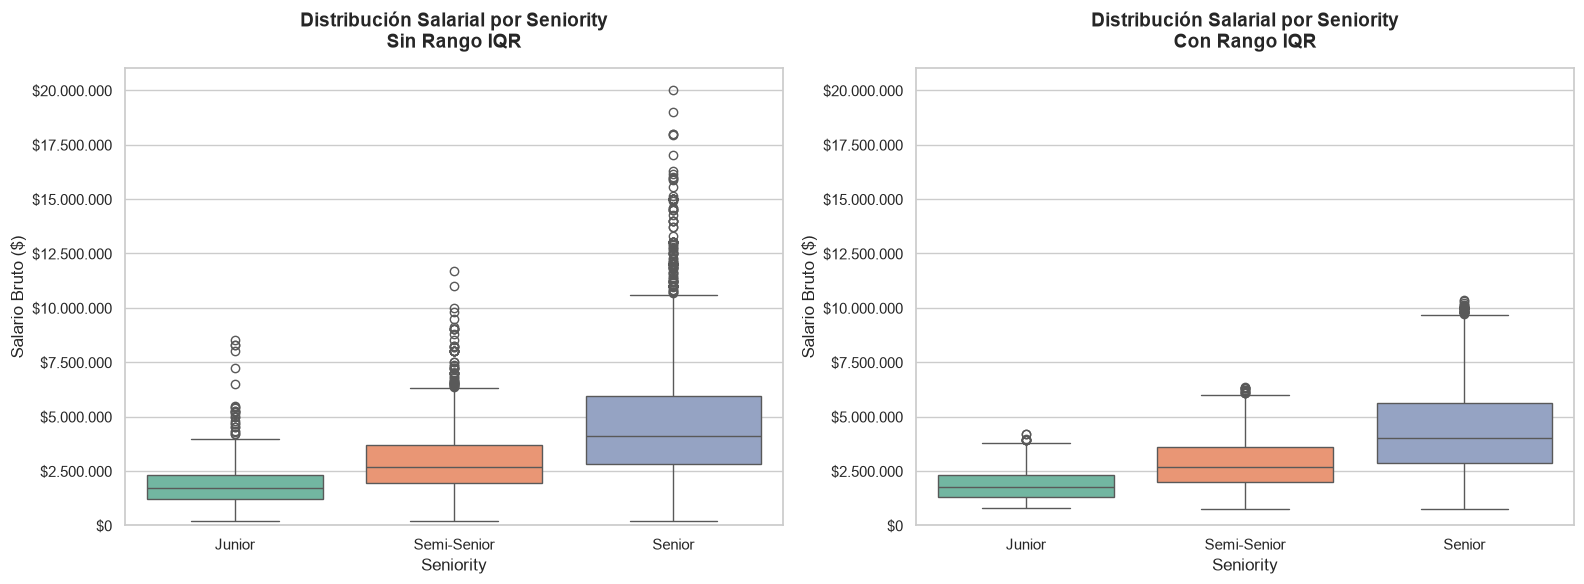

In [126]:
# Gráficos de Caja por Seniority: Antes y Después del Rango IQR
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Configuración visual general
sns.set_theme(style="whitegrid")

# Creamos dos gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Orden de los niveles
orden_seniority = ['Junior', 'Semi-Senior', 'Senior']

# =========================
# Gráfico SIN Rango IQR
# =========================

sns.boxplot(
    data=df_antes_iqr,
    x='seniority',
    y='salario',
    order=orden_seniority,
    palette="Set2",
    ax=axes[0]
)

axes[0].set_title(
    'Distribución Salarial por Seniority\nSin Rango IQR',
    fontsize=14,
    fontweight='bold',
    pad=15
)

axes[0].set_xlabel('Seniority', fontsize=12)
axes[0].set_ylabel('Salario Bruto ($)', fontsize=12)

axes[0].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", "."))
)


# =========================
# Gráfico CON Rango IQR
# =========================

sns.boxplot(
    data=df,
    x='seniority',
    y='salario',
    order=orden_seniority,
    palette="Set2",
    ax=axes[1]
)

axes[1].set_title(
    'Distribución Salarial por Seniority\nCon Rango IQR',
    fontsize=14,
    fontweight='bold',
    pad=15
)

axes[1].set_xlabel('Seniority', fontsize=12)
axes[1].set_ylabel('Salario Bruto ($)', fontsize=12)

axes[1].yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", "."))
)


# =========================
# Misma escala en ambos
# =========================

# Obtenemos el máximo de ambos datasets
max_salario = max(
    df_antes_iqr['salario'].max(),
    df['salario'].max()
)

for ax in axes:
    ax.set_ylim(0, max_salario * 1.05)

plt.tight_layout()
plt.show()

In [127]:
# Agrupación y Resumen Estadístico por Seniority
# Calculamos count, mean, median y std para presenciar la dispersión y tendencia central
stats_seniority = df.groupby('seniority')['salario'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std'
).sort_values(by='median', ascending=False)

# Aplicamos el formato usando .style.format() para las columnas numéricas, usando función global 'formato_moneda' definida en helpers.py
columnas_a_formatear = ['mean', 'median', 'std']
stats_formateadas = stats_seniority.style.format({col: formato_moneda for col in columnas_a_formatear})

print("\nResumen Estadístico del Salario por Seniority:")
display(stats_formateadas)


Resumen Estadístico del Salario por Seniority:


,count,mean,median,std
seniority,,,,
Senior,2635,"$4.380.967,23","$4.000.000,00","$2.023.089,16"
Semi-Senior,1388,"$2.885.364,48","$2.700.000,00","$1.181.273,40"
Junior,444,"$1.909.767,75","$1.764.500,00","$739.716,71"


### ¿Qué mueve realmente la aguja del dinero en el mercado IT?

Una vez entendido el panorama general por *Seniority*, el siguiente paso lógico en nuestro análisis es evaluar cómo influyen las condiciones contractuales y formales del empleo. ¿Cuánto pesa estar contratado bajo relación de dependencia tradicional frente a ser *Contractor*? ¿Existen diferencias abismales según el tipo de contratación?

A continuación, analizaremos el impacto del `tipo_de_contrato` sobre la mediana salarial, permitiéndonos ver qué esquema de contratación lidera la remuneración en el sector.

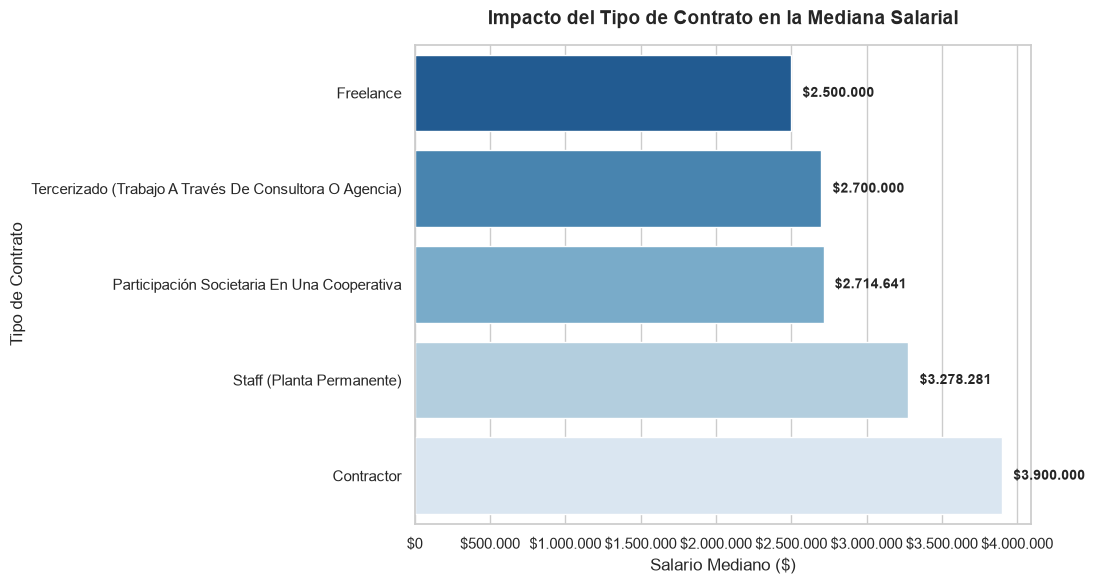

In [128]:
# Visualización: Salario Mediano por Tipo de Contrato
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Calculamos la mediana y la cantidad por tipo de contrato para ordenar el gráfico
contrato_stats = df.groupby('tipo_de_contrato')['salario'].agg(
    mediana='median',
    count='count'
).sort_values(by='mediana', ascending=True)

plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=df,
    y='tipo_de_contrato',
    x='salario',
    order=contrato_stats.index,
    estimator='median',
    palette="Blues_r",
    ci=None
)

plt.title('Impacto del Tipo de Contrato en la Mediana Salarial', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Salario Mediano ($)', fontsize=12)
plt.ylabel('Tipo de Contrato', fontsize=12)

# Formatear el eje X con separadores de miles
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", ".")))

# Añadir etiquetas de valor al final de cada barra
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f"${width:,.0f}".replace(",", "."),
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(8, 0),
                    textcoords='offset points',
                    fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

In [129]:
# Tabla complementaria con métricas de contrato
print("Resumen Estadístico por Tipo de Contrato:")

display(
    df.groupby('tipo_de_contrato')['salario']
    .agg(
        casos='count',
        mediana='median',
        media='mean',
        std='std'
    )
    .sort_values(by='mediana', ascending=False)
    .style.format({
        'mediana': formato_moneda,
        'media': formato_moneda,
        'std': formato_moneda
    })
)

Resumen Estadístico por Tipo de Contrato:


,casos,mediana,media,std
tipo_de_contrato,,,,
Contractor,658,"$3.900.000,00","$4.372.331,85","$2.378.607,62"
Staff (Planta Permanente),3314,"$3.278.281,00","$3.633.498,97","$1.819.485,88"
Participación Societaria En Una Cooperativa,34,"$2.714.640,59","$3.292.328,80","$1.662.197,85"
Tercerizado (Trabajo A Través De Consultora O Agencia),371,"$2.700.000,00","$2.928.530,45","$1.460.312,14"
Freelance,90,"$2.500.000,00","$3.109.305,50","$2.091.738,49"


### ¿Paga mejor la presencialidad o el talento remoto?

Una de las discusiones más recurrentes en la gestión de talento IT es el impacto de la ubicación y la presencialidad. Existe el mito de que las empresas que exigen presencialidad compensan con mejores sueldos para atraer talento a las oficinas, o por el contrario, que el trabajo 100% remoto (asociado muchas veces a la exportación de servicios o contratación internacional) lidera ampliamente la compensación.

A continuación, analizaremos mediante un gráfico de barras horizontales la **mediana salarial** según la modalidad de trabajo para romper mitos con datos concretos del mercado argentino.

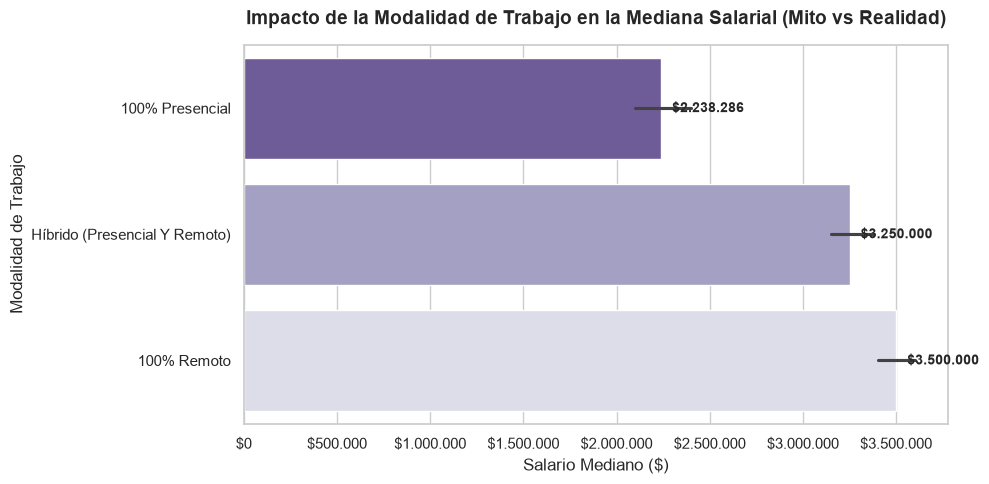

In [130]:
# Visualización: Mediana Salarial por Modalidad de Trabajo
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Agrupamos y calculamos la mediana y métricas por modalidad de trabajo
modalidad_stats = df.groupby('modalidad_de_trabajo')['salario'].agg(
    mediana='median',
    media='mean',
    std='std',
    minimo='min',
    maximo='max',
    count='count'
).sort_values(by='mediana', ascending=True)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=df,
    y='modalidad_de_trabajo',
    x='salario',
    order=modalidad_stats.index,
    estimator='median',
    palette="Purples_r"
)

plt.title('Impacto de la Modalidad de Trabajo en la Mediana Salarial (Mito vs Realidad)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Salario Mediano ($)', fontsize=12)
plt.ylabel('Modalidad de Trabajo', fontsize=12)

# Formatear el eje X con separadores de miles
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", ".")))

# Añadir etiquetas de valor al final de cada barra
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f"${width:,.0f}".replace(",", "."),
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(8, 0),
                    textcoords='offset points',
                    fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

In [131]:
# Tabla Resumen de Modalidades
print("Resumen Estadístico por Modalidad de Trabajo:")

display(
    modalidad_stats.style.format({
        'mediana': formato_moneda,
        'media': formato_moneda,
        'std': formato_moneda,
        'minimo': formato_moneda,
        'maximo': formato_moneda
    })
)

Resumen Estadístico por Modalidad de Trabajo:


,mediana,media,std,minimo,maximo,count
modalidad_de_trabajo,,,,,,
100% Presencial,"$2.238.285,54","$2.655.641,22","$1.595.499,46","$750.000,00","$10.127.000,00",391
Híbrido (Presencial Y Remoto),"$3.250.000,00","$3.645.404,13","$1.863.995,02","$800.000,00","$10.355.004,00",2003
100% Remoto,"$3.500.000,00","$3.886.430,89","$1.973.684,33","$750.000,00","$10.200.000,00",2073


### Tamaño de empresa y Puestos

¿Será que el tamaño de las empresas incide en un mayor salario? ¿Qué puestos llegan más alto económicamente?

In [132]:
# Seleccionar los N trabajos más frecuentes
TOP_N = 10
trabajos_mayoritarios = df['trabajo_de'].value_counts().nlargest(TOP_N).index

# Filtrar el DataFrame asegurando que pertenezcan a los mayoritarios y tengan la dedicación de interés
df_trabajos_mayoritarios = df[
    (df['trabajo_de'].isin(trabajos_mayoritarios)) & 
    (df['dedicacion'] == 'Full-Time')
].copy()

print(f"Trabajos mayoritarios seleccionados: {list(trabajos_mayoritarios)}")

Trabajos mayoritarios seleccionados: ['Developer', 'Sysadmin / Devops / Sre', 'Manager / Director', 'Technical Leader', 'Qa / Tester', 'Bi Analyst / Data Analyst', 'Data Engineer', 'Architect', 'Infosec', 'Business Analyst']


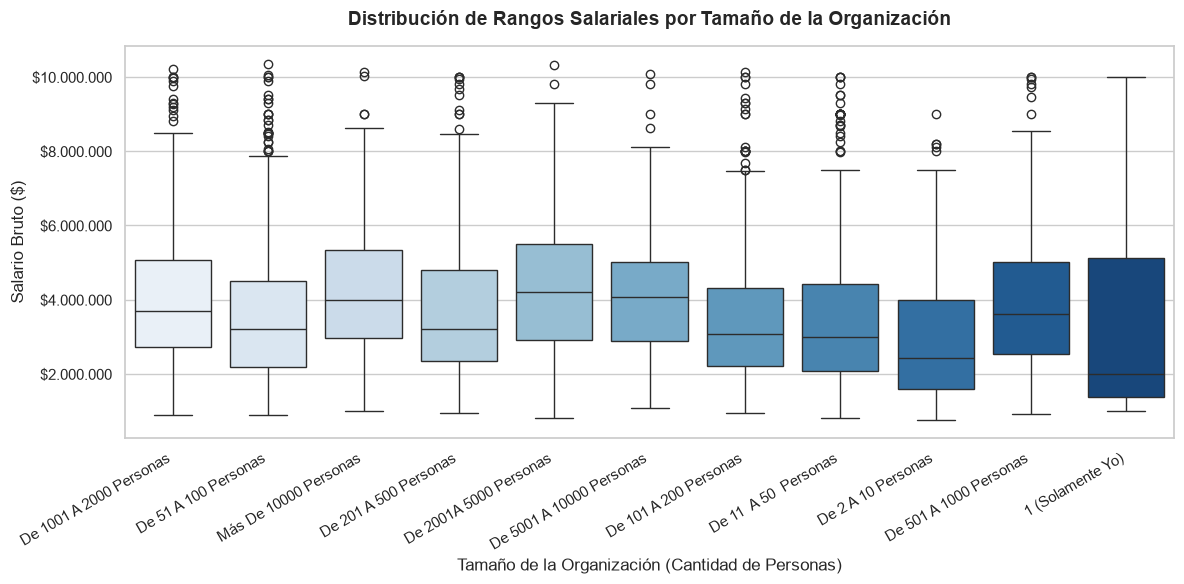

In [133]:
def plot_rango_salarial_empresas(data):
    plt.figure(figsize=(12, 6))
    
    ax = sns.boxplot(
        data=data,
        x='cantidad_de_personas_en_tu_organizacion',
        y='salario',
        palette='Blues'
    )
    
    plt.title(
        'Distribución de Rangos Salariales por Tamaño de la Organización',
        fontsize=14,
        fontweight='bold',
        pad=15
    )
    
    plt.xlabel('Tamaño de la Organización (Cantidad de Personas)', fontsize=12)
    plt.ylabel('Salario Bruto ($)', fontsize=12)
    
    # Rotar etiquetas del eje X si los textos son largos
    plt.xticks(rotation=30, ha='right')
    
    # Formatear el eje Y con formato de moneda
    ax.yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", "."))
    )
    
    plt.tight_layout()
    plt.show()

# Ejecutar la función
plot_rango_salarial_empresas(df_trabajos_mayoritarios)

In [134]:
empresas_stats = df_trabajos_mayoritarios.groupby('cantidad_de_personas_en_tu_organizacion')['salario'].agg(
    mediana='median',
    media='mean',
    std='std',
    minimo='min',
    maximo='max',
    casos='count'
).reset_index()

print("Resumen Estadístico por Tamaño de la Organización:")
display(
    empresas_stats.sort_values(by='mediana', ascending=False)
    .style.format({
        'mediana': formato_moneda,
        'media': formato_moneda,
        'std': formato_moneda,
        'minimo': formato_moneda,
        'maximo': formato_moneda,
        'casos': '{:,}'
    })
)

Resumen Estadístico por Tamaño de la Organización:


,cantidad_de_personas_en_tu_organizacion,mediana,media,std,minimo,maximo,casos
5,De 2001A 5000 Personas,"$4.200.000,00","$4.292.196,14","$1.933.860,77","$800.000,00","$10.310.527,52",237
7,De 5001 A 10000 Personas,"$4.060.373,50","$4.184.933,88","$1.889.187,77","$1.090.000,00","$10.078.034,00",152
10,Más De 10000 Personas,"$4.000.000,00","$4.243.177,88","$1.809.108,88","$1.000.000,00","$10.122.905,00",384
1,De 1001 A 2000 Personas,"$3.700.000,00","$4.205.523,88","$2.052.283,36","$900.000,00","$10.200.000,00",261
8,De 501 A 1000 Personas,"$3.600.000,00","$4.008.486,45","$1.967.318,45","$910.718,00","$10.000.000,00",279
6,De 201 A 500 Personas,"$3.200.000,00","$3.726.382,95","$1.868.888,68","$950.000,00","$10.000.000,00",504
9,De 51 A 100 Personas,"$3.200.000,00","$3.654.584,98","$2.034.662,25","$900.000,00","$10.355.004,00",472
2,De 101 A 200 Personas,"$3.061.456,00","$3.508.012,35","$1.790.662,50","$952.116,30","$10.127.000,00",453
3,De 11 A 50 Personas,"$3.000.000,00","$3.494.285,50","$1.936.965,98","$800.000,00","$10.000.000,00",602
4,De 2 A 10 Personas,"$2.425.000,00","$3.069.954,18","$1.922.479,94","$750.000,00","$9.000.000,00",212


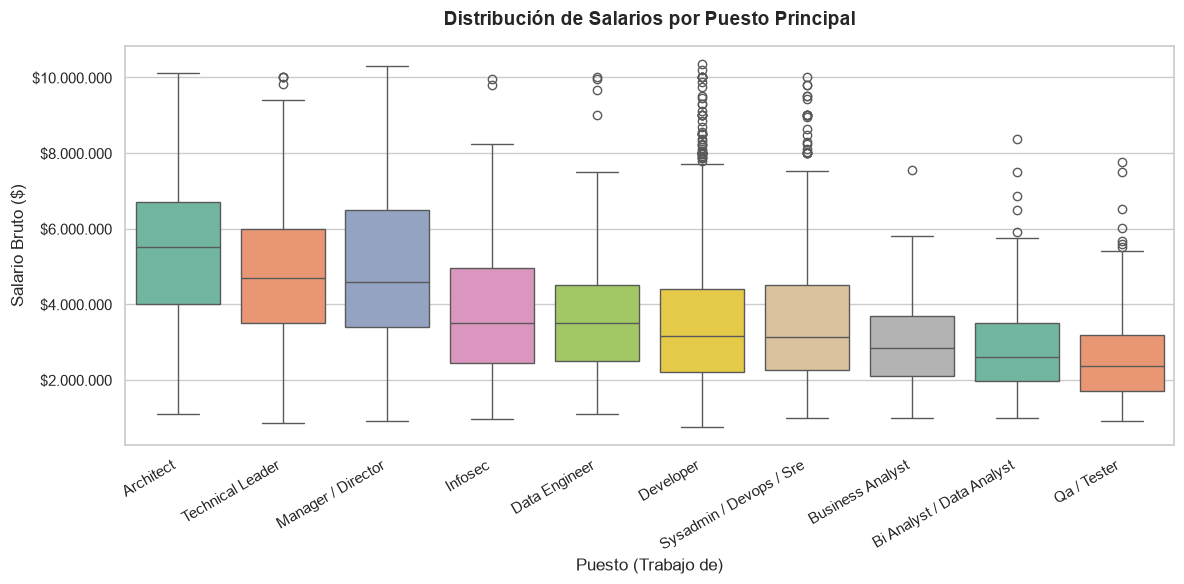

In [135]:
def plot_salario_por_puesto(data):
    plt.figure(figsize=(12, 6))
    
    orden_mediano = data.groupby('trabajo_de')['salario'].median().sort_values(ascending=False).index
    
    ax = sns.boxplot(
        data=data,
        x='trabajo_de',
        y='salario',
        order=orden_mediano,
        palette='Set2'
    )
    
    plt.title(
        'Distribución de Salarios por Puesto Principal',
        fontsize=14,
        fontweight='bold',
        pad=15
    )
    
    plt.xlabel('Puesto (Trabajo de)', fontsize=12)
    plt.ylabel('Salario Bruto ($)', fontsize=12)
    plt.xticks(rotation=30, ha='right')
    
    ax.yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", "."))
    )
    
    plt.tight_layout()
    plt.show()

# Ejecutar gráfico de puestos
plot_salario_por_puesto(df_trabajos_mayoritarios)

In [136]:
puestos_stats = df_trabajos_mayoritarios.groupby('trabajo_de')['salario'].agg(
    mediana='median',
    media='mean',
    std='std',
    minimo='min',
    maximo='max',
    casos='count'
).reset_index()

print("Resumen Estadístico por Puesto Principal:")
display(
    puestos_stats.sort_values(by='mediana', ascending=False)
    .style.format({
        'mediana': formato_moneda,
        'media': formato_moneda,
        'std': formato_moneda,
        'minimo': formato_moneda,
        'maximo': formato_moneda,
        'casos': '{:,}'
    })
)

Resumen Estadístico por Puesto Principal:


,trabajo_de,mediana,media,std,minimo,maximo,casos
0,Architect,"$5.500.000,00","$5.588.522,95","$2.099.640,28","$1.100.000,00","$10.122.905,00",117
9,Technical Leader,"$4.700.000,00","$4.848.459,01","$1.974.434,42","$850.000,00","$10.000.000,00",316
6,Manager / Director,"$4.600.000,00","$5.009.538,61","$2.194.411,19","$900.000,00","$10.310.527,52",381
5,Infosec,"$3.500.200,00","$3.917.821,99","$2.063.625,48","$950.000,00","$9.945.800,00",108
3,Data Engineer,"$3.500.000,00","$3.781.969,61","$1.753.720,02","$1.100.000,00","$10.000.000,00",133
4,Developer,"$3.154.000,00","$3.487.364,34","$1.761.890,18","$750.000,00","$10.355.004,00","1,520"
8,Sysadmin / Devops / Sre,"$3.126.923,00","$3.589.507,42","$1.834.374,67","$980.000,00","$10.000.000,00",508
2,Business Analyst,"$2.834.000,00","$3.033.662,58","$1.182.879,42","$1.000.000,00","$7.562.000,00",105
1,Bi Analyst / Data Analyst,"$2.600.000,00","$2.875.018,28","$1.327.784,86","$990.000,00","$8.376.500,00",172
7,Qa / Tester,"$2.369.603,00","$2.584.048,24","$1.238.899,28","$910.717,00","$7.750.000,00",220


### ¿Qué tecnologías mueven la aguja técnica y salarial?

Avanzando en nuestra comprensión de los factores estructurales del salario, llegamos al núcleo técnico: las herramientas, lenguajes y frameworks que utilizan los profesionales. Al momento de entrenar modelos predictivos de salarios, las tecnologías son *features* clave y altamente discriminantes. 

A continuación, visualizaremos un gráfico de barras horizontales con el **top de tecnologías con mayor salario mediano** en el mercado argentino, permitiéndonos identificar los nichos de mayor valor agregado.

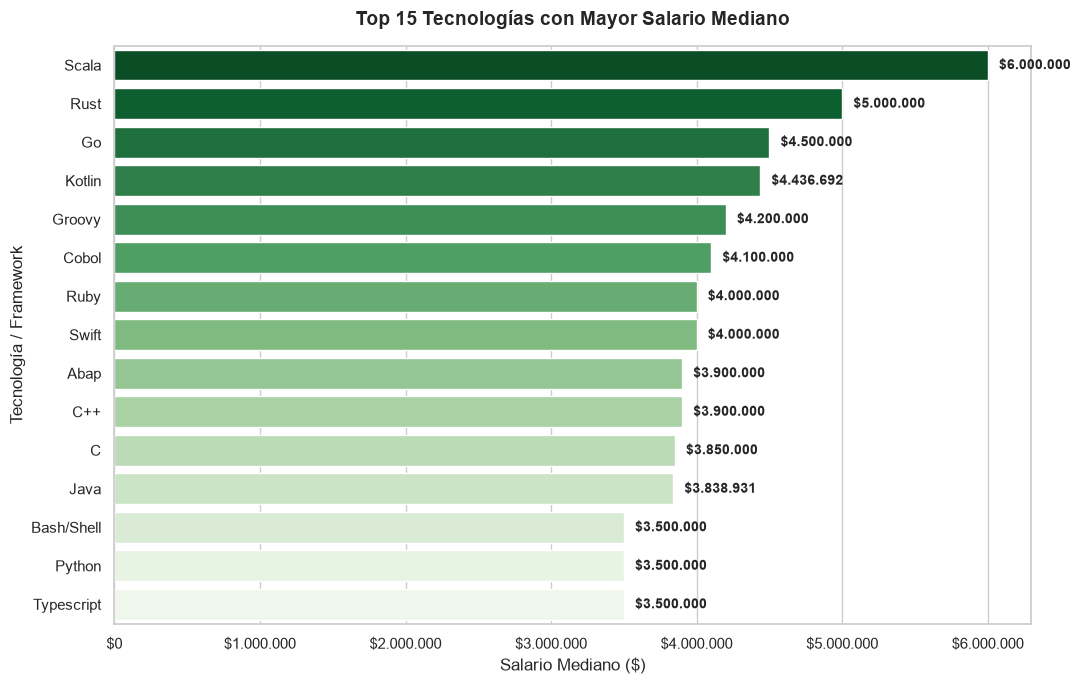

In [137]:
# Visualización: Top Tecnologías Mejor Pagas
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import pandas as pd

# Nota: Asumimos que existe una columna o listado de tecnologías (ej. 'lenguajes_de_programacion' o similar). 
# Si tu dataset maneja una columna separada por comas, primero haríamos un explode. 
# Aquí usamos 'lenguajes' como ejemplo estándar de la encuesta sysarmy.

columna_tecnologia = 'lenguajes' if 'lenguajes' in df.columns else [c for c in df.columns if 'lenguaje' in c or 'tecnologia' in c][0]

# Si las tecnologías están separadas por comas en un string, las separamos:
df_tech = df.assign(tech=df[columna_tecnologia].str.split(',')).explode('tech')
df_tech['tech'] = df_tech['tech'].str.strip()

# Calculamos la mediana y el conteo por tecnología, filtrando aquellas con una muestra representativa (ej. más de 20 casos)
tech_stats = df_tech.groupby('tech')['salario'].agg(
    mediana='median',
    media='mean',
    std='std',
    minimo='min',
    maximo='max',
    casos='count'
).query('casos >= 20').sort_values(by='mediana', ascending=False).head(15)

plt.figure(figsize=(11, 7))
ax = sns.barplot(
    data=tech_stats.reset_index(),
    y='tech',
    x='mediana',
    palette="Greens_r"
)

plt.title('Top 15 Tecnologías con Mayor Salario Mediano', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Salario Mediano ($)', fontsize=12)
plt.ylabel('Tecnología / Framework', fontsize=12)

# Formatear el eje X con separadores de miles
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", ".")))

# Añadir etiquetas de valor al final de cada barra
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f"${width:,.0f}".replace(",", "."),
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(8, 0),
                    textcoords='offset points',
                    fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

In [138]:
# Tabla Resumen del Top Tecnológico
print("Resumen Estadístico del Top Tecnológico:")

display(
    tech_stats.sort_values(by='mediana', ascending=False)
    .style.format({
        'mediana': formato_moneda,
        'media': formato_moneda,
        'std': formato_moneda,
        'minimo': formato_moneda,
        'maximo': formato_moneda
    })
)

Resumen Estadístico del Top Tecnológico:


,mediana,media,std,minimo,maximo,casos
tech,,,,,,
Scala,"$6.000.000,00","$6.321.877,41","$2.041.654,21","$2.440.000,00","$10.000.000,00",26
Rust,"$5.000.000,00","$4.983.242,48","$2.500.100,78","$1.155.600,00","$10.000.000,00",27
Go,"$4.500.000,00","$4.946.620,44","$2.197.450,46","$1.080.000,00","$10.200.000,00",234
Kotlin,"$4.436.692,00","$4.789.824,19","$2.137.024,81","$750.000,00","$9.952.800,00",122
Groovy,"$4.200.000,00","$4.378.698,43","$1.890.436,65","$1.727.426,00","$9.000.000,00",61
Cobol,"$4.100.000,00","$3.950.966,71","$1.866.124,29","$1.200.000,00","$9.000.000,00",47
Ruby,"$4.000.000,00","$4.469.318,12","$2.085.616,24","$1.275.375,00","$10.000.000,00",51
Swift,"$4.000.000,00","$4.434.056,27","$2.027.589,06","$1.421.000,00","$10.000.000,00",54
Abap,"$3.900.000,00","$4.114.084,44","$2.242.695,73","$1.000.000,00","$9.995.000,00",36


### Radiografía de género: Desentrañando las causas de la brecha

Para cerrar nuestro análisis estructural del mercado IT, abordamos una dimensión social y de recursos humanos de gran relevancia: **la brecha de género**. 

Frente a una diferencia salarial global entre géneros, el análisis de datos moderno nos exige ir más allá del promedio superficial para responder a una pregunta clave: *¿Esta brecha existe porque se le paga menos a un género por realizar exactamente el mismo trabajo, o responde a un "techo de cristal" donde hay menor representación femenina en puestos jerárquicos de alta compensación (Managers, Directors, Leads)?*

A continuación, implementaremos un enfoque visual de dos paneles (*subplots*): el primero para contrastar la **mediana salarial por género**, y el segundo para medir el **porcentaje de puestos jerárquicos** que ocupa cada género.

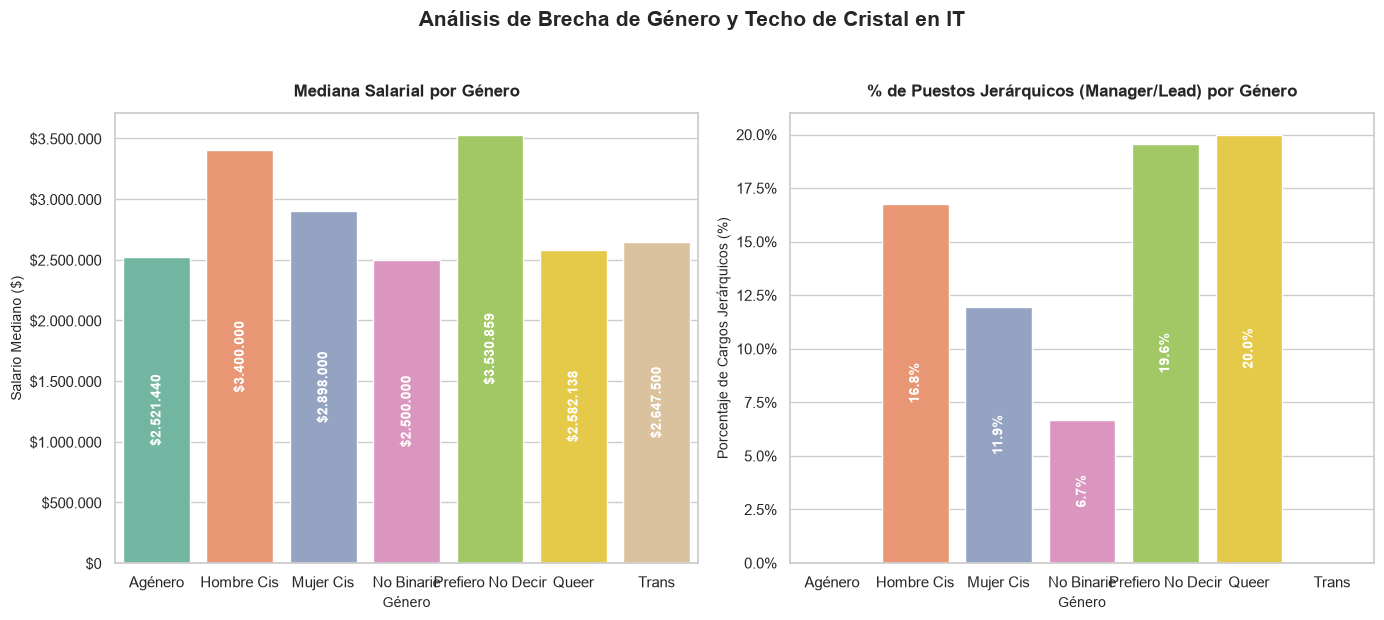

In [139]:
# Visualización: Brecha Salarial y Representación Jerárquica por Género
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import numpy as np

# Aseguramos que la columna de género esté estandarizada
if 'genero' in df.columns:
    # Agrupamos los géneros minoritarios si es necesario o nos enfocamos en los principales para visualización clara
    pass

# Identificamos puestos jerárquicos (Manager, Director, Líder, C-Level, etc.)
# Buscamos palabras clave en la columna de puestos o trabajo_de
col_puesto = 'trabajo_de' if 'trabajo_de' in df.columns else [c for c in df.columns if 'puesto' in c or 'cargo' in c][0]
palabras_jerarquia = ['manager', 'director', 'lead', 'jefe', 'head', 'chief', 'c-level', 'gerente']
patron_jerarquia = '|'.join(palabras_jerarquia)

df['es_jerarquico'] = df[col_puesto].str.lower().str.contains(patron_jerarquia, na=False)

# Preparamos las métricas por género
genero_stats = df.groupby('genero').agg(
    mediana_salario=('salario', 'median'),
    media_salario=('salario', 'mean'),
    std_salario=('salario', 'std'),
    minimo_salario=('salario', 'min'),
    maximo_salario=('salario', 'max'),
    porcentaje_jerarquicos=(
        'es_jerarquico',
        lambda x: (x.sum() / len(x)) * 100
    ),
    total_casos=('salario', 'count')
).reset_index()

# Creamos una figura con dos subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Mediana Salarial por Género
sns.barplot(
    data=genero_stats,
    x='genero',
    y='mediana_salario',
    ax=axes[0],
    palette="Set2",
    legend=False
)
axes[0].set_title('Mediana Salarial por Género', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Género', fontsize=10)
axes[0].set_ylabel('Salario Mediano ($)', fontsize=10)
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", ".")))

# Etiquetas de valor en el Gráfico 1
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f"${height:,.0f}".replace(",", "."),
                         (p.get_x() + p.get_width() / 2., height / 2),
                         ha='center', va='center',
                         rotation=90, fontsize=10, fontweight='semibold', color='white')

# Gráfico 2: Porcentaje de Puestos Jerárquicos por Género
sns.barplot(
    data=genero_stats,
    x='genero',
    y='porcentaje_jerarquicos',
    ax=axes[1],
    palette="Set2",
    legend=False
)
axes[1].set_title('% de Puestos Jerárquicos (Manager/Lead) por Género', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Género', fontsize=10)
axes[1].set_ylabel('Porcentaje de Cargos Jerárquicos (%)', fontsize=10)
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{x:.1f}%"))

# Etiquetas de valor en el Gráfico 2
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f"{height:.1f}%",
                         (p.get_x() + p.get_width() / 2., height / 2),
                         ha='center', va='center',
                         rotation=90, fontsize=10, fontweight='semibold', color='white')

plt.suptitle('Análisis de Brecha de Género y Techo de Cristal en IT', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

In [140]:
# Tabla Resumen de Género
print("Resumen Estadístico por Género:")

display(
    genero_stats.style.format({
        'mediana_salario': formato_moneda,
        'media_salario': formato_moneda,
        'std_salario': formato_moneda,
        'minimo_salario': formato_moneda,
        'maximo_salario': formato_moneda,
        'porcentaje_jerarquicos': '{:.1f}%',
        'total_casos': '{:,.0f}'
    })
)

Resumen Estadístico por Género:


,genero,mediana_salario,media_salario,std_salario,minimo_salario,maximo_salario,porcentaje_jerarquicos,total_casos
0,Agénero,"$2.521.440,00","$2.521.440,00",,"$2.521.440,00","$2.521.440,00",0.0%,1
1,Hombre Cis,"$3.400.000,00","$3.769.905,08","$1.949.664,56","$750.000,00","$10.310.527,52",16.8%,"3,489"
2,Mujer Cis,"$2.898.000,00","$3.281.126,57","$1.750.797,43","$750.000,00","$10.355.004,00",11.9%,897
3,No Binarie,"$2.500.000,00","$2.802.049,58","$1.300.377,30","$1.200.000,00","$5.880.168,00",6.7%,15
4,Prefiero No Decir,"$3.530.859,16","$4.182.027,58","$2.281.783,13","$1.000.000,00","$10.000.000,00",19.6%,46
5,Queer,"$2.582.138,50","$3.349.993,80","$2.047.762,42","$1.000.000,00","$7.200.000,00",20.0%,10
6,Trans,"$2.647.500,00","$3.234.582,50","$1.776.230,99","$2.031.660,00","$7.450.000,00",0.0%,8


### ¿Qué está pasando con "Prefiero No Decir"?

Son 80 casos contra 3490 de hombres y 897 de mujeres, inflan artificialmente la mediana y el porcentaje de puestos jerárquicos.

No sirve como categoría demográfica real ya que "Prefiero No Decir" no es una identidad de género, sino una negativa a responder.

Debido a la naturaleza del modelo que queremos construir, esta categoría no nos sirve por lo que hemos de excluirla.

In [141]:
# Filtramos para quedarnos únicamente con las categorías de género representativas
df = df[~df['genero'].isin(['Prefiero No Decir', 'No Binarie', 'Queer', 'Trans', 'Agénero'])]

#### ¿Existe una relación entre la edad y el salario?

Una de las preguntas que podemos plantearnos al analizar los salarios del sector IT es si los ingresos tienden a aumentar a medida que las personas envejecen. A primera vista, podría suponerse que una mayor edad está asociada con más experiencia laboral, mayor antigüedad y puestos de mayor responsabilidad. Sin embargo, estas relaciones no necesariamente se cumplen en todos los casos

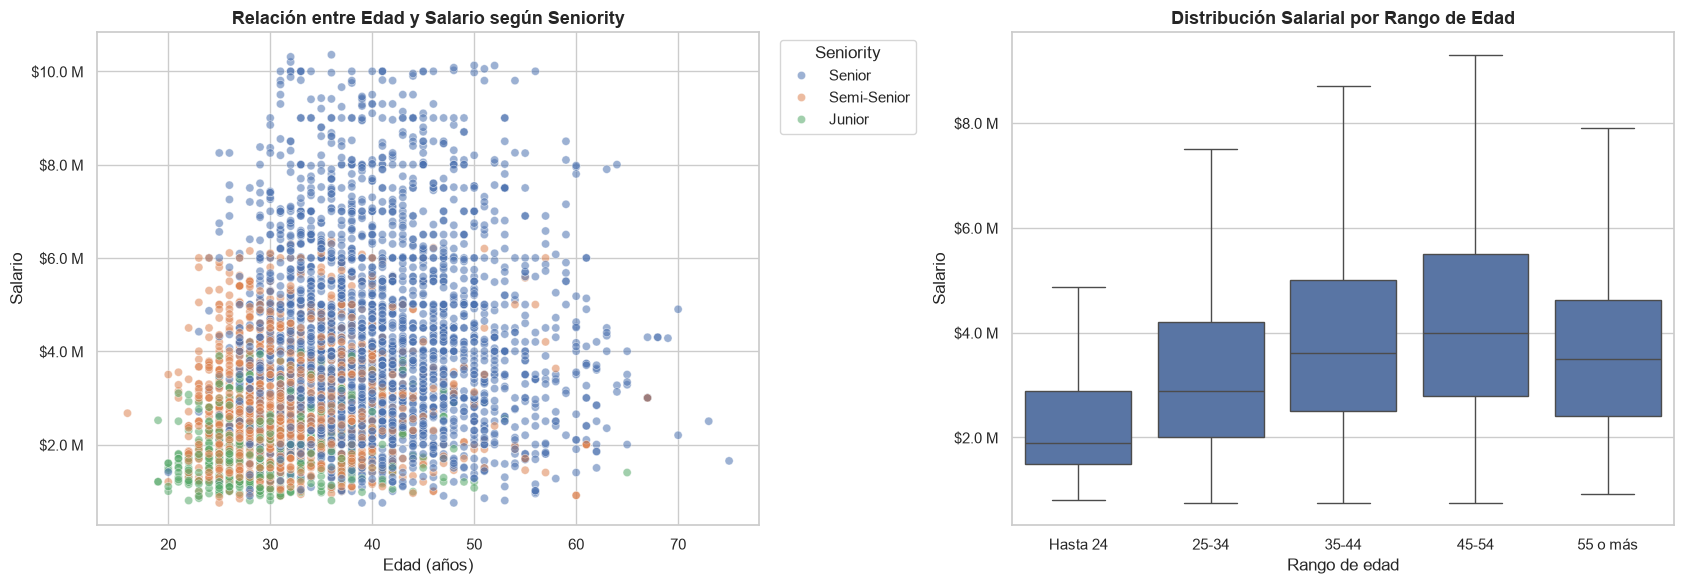

In [142]:
# Exploración: Relación entre Edad y Salario
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import pandas as pd
import numpy as np

# Preparamos los datos sin modificar el DataFrame original
df_edad = df[['tengo_edad', 'salario', 'seniority']].copy()

df_edad['tengo_edad'] = pd.to_numeric(
    df_edad['tengo_edad'], errors='coerce'
)
df_edad['salario'] = pd.to_numeric(
    df_edad['salario'], errors='coerce'
)

df_edad = df_edad.dropna(
    subset=['tengo_edad', 'salario']
)

# Agrupamos las edades para facilitar la comparación
limites_edad = [0, 24, 34, 44, 54, 120]
etiquetas_edad = [
    'Hasta 24',
    '25-34',
    '35-44',
    '45-54',
    '55 o más'
]

df_edad['rango_edad'] = pd.cut(
    df_edad['tengo_edad'],
    bins=limites_edad,
    labels=etiquetas_edad,
    include_lowest=True
)

# Excluimos edades fuera de los rangos definidos para los gráficos
df_edad = df_edad.dropna(subset=['rango_edad'])

# Formato monetario para el eje salarial
formato_eje = ticker.FuncFormatter(
    lambda valor, posicion: f'${valor / 1_000_000:.1f} M'
)

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# --------------------------------------------------
# GRÁFICO 1: Edad vs. Salario
# --------------------------------------------------
sns.scatterplot(
    data=df_edad,
    x='tengo_edad',
    y='salario',
    hue='seniority',
    alpha=0.55,
    s=35,
    ax=axes[0]
)

axes[0].set_title(
    'Relación entre Edad y Salario según Seniority',
    fontsize=13,
    fontweight='bold'
)
axes[0].set_xlabel('Edad (años)')
axes[0].set_ylabel('Salario')
axes[0].yaxis.set_major_formatter(formato_eje)
axes[0].legend(title='Seniority', bbox_to_anchor=(1.02, 1),
               loc='upper left')

# --------------------------------------------------
# GRÁFICO 2: Distribución salarial por rango de edad
# --------------------------------------------------
sns.boxplot(
    data=df_edad,
    x='rango_edad',
    y='salario',
    order=etiquetas_edad,
    showfliers=False,
    ax=axes[1]
)

axes[1].set_title(
    'Distribución Salarial por Rango de Edad',
    fontsize=13,
    fontweight='bold'
)
axes[1].set_xlabel('Rango de edad')
axes[1].set_ylabel('Salario')
axes[1].yaxis.set_major_formatter(formato_eje)

plt.tight_layout()
plt.show()


In [143]:
# Tabla Resumen del Top Edad
resumen_edad = df_edad.groupby(
    'rango_edad', observed=False
)['salario'].agg(
    casos='count',
    mediana='median',
    media='mean',
    std='std',
    minimo='min',
    maximo='max'
)

print("Resumen salarial por rango de edad:")
display(
    resumen_edad .style.format({
            'mediana': formato_moneda,
            'media': formato_moneda,
            'std': formato_moneda,
            'minimo': formato_moneda,
            'maximo': formato_moneda
    })
)

Resumen salarial por rango de edad:


,casos,mediana,media,std,minimo,maximo
rango_edad,,,,,,
Hasta 24,194,"$1.900.000,00","$2.258.371,95","$1.053.328,30","$800.000,00","$6.000.000,00"
25-34,1699,"$2.890.000,00","$3.286.216,34","$1.736.533,05","$750.000,00","$10.310.527,52"
35-44,1617,"$3.610.000,00","$3.984.579,05","$1.978.463,95","$750.000,00","$10.355.004,00"
45-54,695,"$3.990.000,00","$4.252.080,95","$2.039.840,57","$750.000,00","$10.127.000,00"
55 o más,182,"$3.500.000,00","$3.740.126,70","$1.812.549,91","$910.717,00","$10.000.000,00"


### ¿Influye la geografía en el salario dentro del mercado IT argentino?

Para cerrar nuestra exploración de los factores estructurales y contextuales que moldean los sueldos, analizamos la **dimensión geográfica** (`donde_estas_trabajando` o provincia). A pesar de que la industria tecnológica se caracteriza por la alta adopción del trabajo remoto, existen diferencias significativas impulsadas por el radicado de las empresas, los polos tecnológicos regionales (como CABA, Córdoba, Santa Fe o Neuquén) y las políticas de compensación local frente a contratos internacionales.

A continuación, visualizaremos mediante un gráfico de cajas (*boxplot*) o gráfico de barras ordenado el comportamiento de los salarios según las principales provincias del país, manteniendo el filtro limpio de géneros no declarados y extremos salariales.

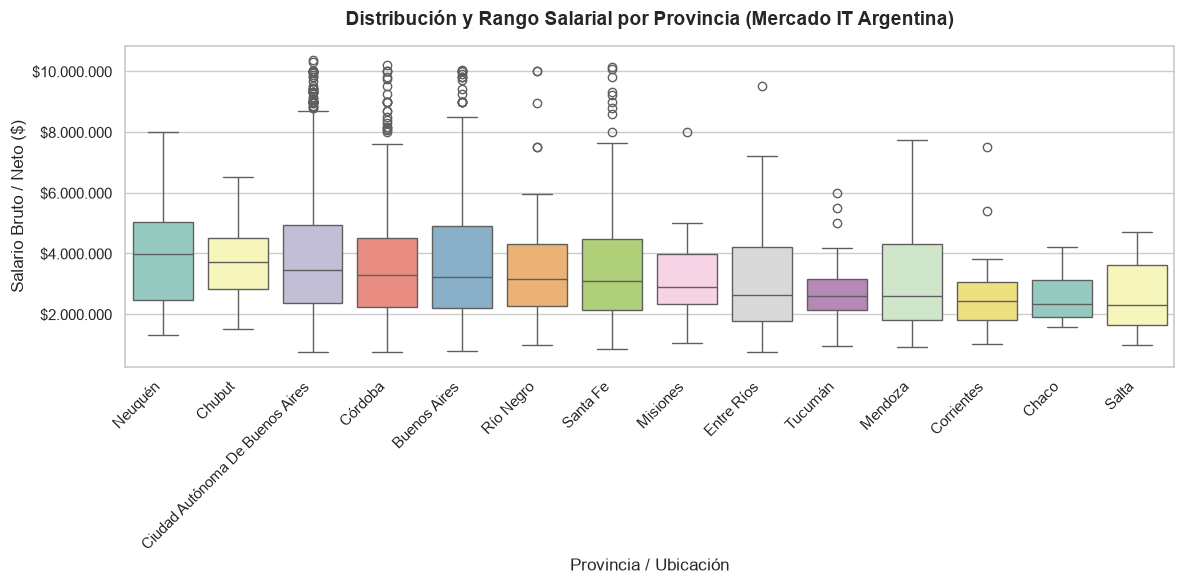

In [144]:
# Visualización: Rango Salarial por Provincia (Top Provincias con mayor volumen)
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# 1. Identificamos la columna de provincia/ubicación correcta
col_provincia = 'donde_estas_trabajando' if 'donde_estas_trabajando' in df.columns else [c for c in df.columns if 'provincia' in c or 'ubicacion' in c][0]

# 2. Nos quedamos con las provincias que tengan una muestra representativa (ej. más de 20 casos) para evitar ruido
top_provincias = df[col_provincia].value_counts()[lambda x: x >= 20].index
df_prov = df[df[col_provincia].isin(top_provincias)]

# Calculamos la mediana por provincia para ordenar el gráfico de manera descendente
prov_orden = df_prov.groupby(col_provincia)['salario'].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
ax = sns.boxplot(
    data=df_prov,
    x=col_provincia,
    y='salario',
    order=prov_orden,
    palette="Set3"
)

plt.title('Distribución y Rango Salarial por Provincia (Mercado IT Argentina)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Provincia / Ubicación', fontsize=12)
plt.ylabel('Salario Bruto / Neto ($)', fontsize=12)
plt.xticks(rotation=45, ha='right')

# Formatear el eje Y con separadores de miles
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", ".")))

plt.tight_layout()
plt.show()

In [145]:
# Tabla Resumen Estadístico por Provincia
prov_stats = df_prov.groupby(col_provincia)['salario'].agg(
    casos='count',
    mediana='median',
    media='mean',
    std='std',
    minimo='min',
    maximo='max'
).sort_values(by='mediana', ascending=False)

print("Resumen Estadístico del Salario por Provincia:")
display(prov_stats.style.format({
    'mediana': formato_moneda,
    'media': formato_moneda,
    'std': formato_moneda,
    'minimo': formato_moneda,
    'maximo': formato_moneda
}))

Resumen Estadístico del Salario por Provincia:


,casos,mediana,media,std,minimo,maximo
donde_estas_trabajando,,,,,,
Neuquén,34,"$3.966.000,00","$3.944.964,47","$1.675.779,00","$1.303.796,00","$8.000.000,00"
Chubut,22,"$3.718.674,50","$3.694.562,12","$1.251.577,99","$1.522.238,44","$6.500.000,00"
Ciudad Autónoma De Buenos Aires,2202,"$3.450.000,00","$3.831.803,70","$1.957.946,26","$750.000,00","$10.355.004,00"
Córdoba,398,"$3.277.200,00","$3.672.505,19","$1.966.965,67","$750.000,00","$10.200.000,00"
Buenos Aires,926,"$3.213.798,50","$3.670.887,59","$1.954.419,63","$800.000,00","$10.052.126,00"
Río Negro,52,"$3.159.145,00","$3.646.125,63","$2.106.391,16","$970.000,00","$10.000.000,00"
Santa Fe,311,"$3.100.000,00","$3.449.655,42","$1.805.545,13","$850.000,00","$10.127.000,00"
Misiones,37,"$2.900.000,00","$3.155.227,35","$1.379.961,21","$1.051.000,00","$8.000.000,00"
Entre Ríos,62,"$2.629.357,00","$3.172.764,54","$1.886.355,38","$750.000,00","$9.500.000,00"


#### Matriz de Correlación

Observaremos el mapa de calor entre las columnas seleccionadas.

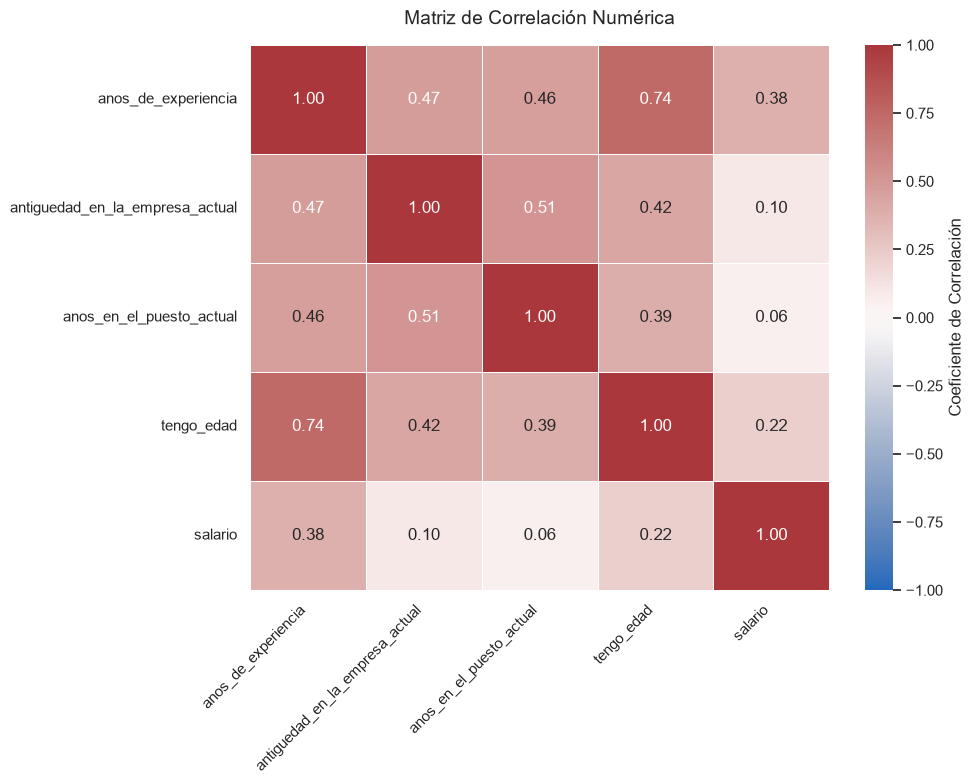

In [146]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionamos únicamente las columnas numéricas del DataFrame
df_num = df.select_dtypes(include=[np.number])

# Calculamos la matriz de correlación completa
matriz_corr = df_num.corr()

# Configuramos la figura para ver la cuadrícula
plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr, 
    annot=True, 
    cmap='vlag', 
    vmin=-1, 
    vmax=1, 
    fmt='.2f',
    linewidths=0.5,
    cbar_kws={'label': 'Coeficiente de Correlación'}
)

plt.title('Matriz de Correlación Numérica', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### Conclusiones de Matriz de Correlación

**¿Qué variables están más relacionadas con el salario?**

| Variable | Porcentaje
|---|---|
| `anos_de_experiencia` | 0.38 |
| `tengo_edad` | 0.16 |
| `antiguedad_en_la_empresa_actual` | 0.10 |

De las mejores relaciones presentes, los años de experiencia son los que presentan una relación lineal más clara con el salario. Sin embargo, una correlación de 0,38 no implica que el salario aumente un 38% con cada año de experiencia.

**¿Qué otras relaciones se observan?**

* `anos_de_experiencia` y `tengo_edad`: correlación de **0,51**.
* `antiguedad_en_la_empresa_actual` y `anos_en_el_puesto_actual`: correlación de **0,51**.
* `anos_de_experiencia` y `antiguedad_en_la_empresa_actual`: correlación de **0,47**.

Relaciones con sentido dado que con más edad se acumula más experiencia, y quienes llevan más tiempo en una empresa pueden llevar más tiempo en su puesto. No es necesariamente redundante, pero debemos tenerlo en cuenta al entrenar el modelo.

In [147]:
# Exportar el DataFrame limpio a un archivo CSV
df.to_csv('../data/dataset_clean.csv', index=False)

print("¡Archivo exportado exitosamente en 'data/dataset_clean.csv'!")

¡Archivo exportado exitosamente en 'data/dataset_clean.csv'!
